In [1]:
import time
import tracemalloc
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn import metrics


In [2]:
df = pd.read_csv('../data/komdigi_hoaks.csv')
df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

print(f"Total data bersih siap klasterisasi: {len(df)} baris")
df[['title', 'teks']].head()


Total data bersih siap klasterisasi: 4176 baris


,title,teks
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


In [3]:
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks'])
X_dense = X.toarray()

print("Bentuk matriks data:", X_dense.shape)


Bentuk matriks data: (4176, 1000)


In [4]:
# Penentuan Parameter HDBSCAN (Manhattan)
# Menggunakan min_cluster_size = 15 untuk menyeimbangkan pembentukan klaster tematik dan pembuangan noise
min_cluster_size = 15
print(f"Parameter konfigurasi HDBSCAN: min_cluster_size = {min_cluster_size}, metric = 'manhattan'")


Parameter konfigurasi HDBSCAN: min_cluster_size = 15, metric = 'manhattan'


In [5]:
# Mulai pelacakan memori & waktu
tracemalloc.start()
waktu_mulai = time.time()

hdb = HDBSCAN(min_cluster_size=15, metric='manhattan', copy=True)
df['hdbscan_manhattan'] = hdb.fit_predict(X_dense)

waktu_selesai = time.time()
mem_sekarang, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

labels = df['hdbscan_manhattan']
hasil_jumlah_klaster = len(set(labels)) - (1 if -1 in labels else 0)
jumlah_noise = (labels == -1).sum()

hasil_waktu = waktu_selesai - waktu_mulai
hasil_memori_mb = mem_puncak / (1024 * 1024)

if hasil_jumlah_klaster > 1:
    hasil_silhouette = metrics.silhouette_score(X_dense, labels, metric='manhattan')
    mask_valid = labels != -1
    hasil_dbi = metrics.davies_bouldin_score(X_dense[mask_valid], labels[mask_valid]) if len(set(labels[mask_valid])) > 1 else 0.0
else:
    hasil_silhouette = 0.0
    hasil_dbi = 0.0

print("=" * 45)
print("HASIL PENGUJIAN: HDBSCAN MANHATTAN")
print("=" * 45)
print(f"1. Jumlah Klaster   : {hasil_jumlah_klaster} klaster (dan {jumlah_noise} data noise)")
print(f"2. Waktu Eksekusi    : {hasil_waktu:.4f} detik")
print(f"3. Silhouette Score : {hasil_silhouette:.4f} (metrik manhattan)")
print(f"4. Penggunaan Memori: {hasil_memori_mb:.2f} MB")
print(f"5. Davies-Bouldin   : {hasil_dbi:.4f} (pada data terklaster)")
print("=" * 45)


HASIL PENGUJIAN: HDBSCAN MANHATTAN
1. Jumlah Klaster   : 3 klaster (dan 1122 data noise)
2. Waktu Eksekusi    : 41.3787 detik
3. Silhouette Score : 0.1599 (metrik manhattan)
4. Penggunaan Memori: 4.06 MB


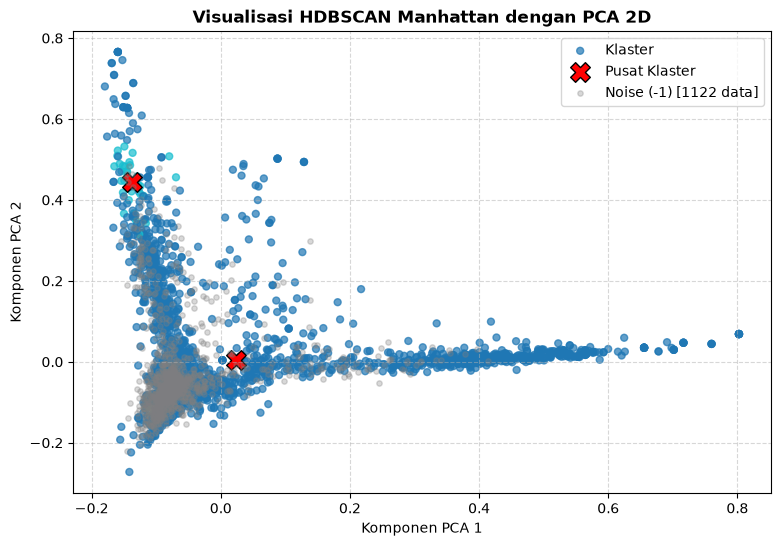

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_dense)

df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

non_noise = df[df['hdbscan_manhattan'] != -1]
if len(non_noise) > 0:
    plt.scatter(
        non_noise['pca1'],
        non_noise['pca2'],
        c=non_noise['hdbscan_manhattan'],
        cmap='tab10',
        s=25,
        alpha=0.7,
        label='Klaster',
    )
    for i, c in enumerate(sorted(non_noise['hdbscan_manhattan'].unique())):
        pusat_x = non_noise[non_noise['hdbscan_manhattan'] == c]['pca1'].mean()
        pusat_y = non_noise[non_noise['hdbscan_manhattan'] == c]['pca2'].mean()
        plt.scatter(
            pusat_x,
            pusat_y,
            marker='X',
            s=200,
            color='red',
            edgecolors='black',
            label='Pusat Klaster' if i == 0 else '',
        )

noise = df[df['hdbscan_manhattan'] == -1]
if len(noise) > 0:
    plt.scatter(
        noise['pca1'],
        noise['pca2'],
        color='gray',
        s=15,
        alpha=0.3,
        label=f'Noise (-1) [{len(noise)} data]',
    )

plt.title('Visualisasi HDBSCAN Manhattan dengan PCA 2D', fontsize=12, fontweight='bold')
plt.xlabel('Komponen PCA 1')
plt.ylabel('Komponen PCA 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [7]:
terms = tfidf.get_feature_names_out()
unique_clusters = sorted(df['hdbscan_manhattan'].unique())

print("Kata Kunci Dominan Tiap Klaster HDBSCAN Manhattan:")
for c in unique_clusters:
    if c == -1:
        nama = "NOISE / OUTLIER"
    else:
        nama = f"Klaster {c}"
    
    idx = df[df['hdbscan_manhattan'] == c].index
    if len(idx) > 0:
        mean_tfidf = np.asarray(X_dense[idx].mean(axis=0)).flatten()
        top_terms = [terms[i] for i in mean_tfidf.argsort()[::-1][:7]]
        print(f"[{nama}] ({len(idx)} data): {', '.join(top_terms)}")


Kata Kunci Dominan Tiap Klaster HDBSCAN Manhattan:
[NOISE / OUTLIER] (1122 data): yang, dan, tidak, tersebut, di, video, hoaks
[Klaster 0] (3020 data): hoaks, mengatasnamakan, akun, whatsapp, di, tautan, video
[Klaster 1] (34 data): tautan, data, pribadi, telegram, mengarah, meminta, nama
